# Projet Data Mining — Analyse des données `health`

* Groupe : Groupe 10
* Membres : Tanguy VALLOT, *(à compléter)*

Ce notebook part des fichiers nettoyés dans `01_nettoyage_health.ipynb` (`data/health_clean/`). Il suit l'ordre des cours : chaque partie applique les méthodes d'un cours aux données médicales.

*Usage de l'IA générative : notebook écrit avec l'aide de Claude (Anthropic) pour le code et la mise en forme ; le plan et les interprétations ont été discutés et validés par le groupe.*

## Cours 1 — Comprendre ses données

Le cours propose d'identifier d'abord le type de chaque variable, puis de décrire les variables numériques (statistiques et histogrammes) et nominales (diagrammes en barres), et enfin de chercher les corrélations entre variables et de regarder la forme de ces relations.

### 1.1 Les deux tableaux d'analyse

Les mesures ne sont pas toutes prises au même rythme : 14 sont prises à chaque consultation, 18 une seule fois par patient. On construit donc deux tableaux :
* **par consultation** (1 067 lignes) : les mesures répétées et l'âge du patient au moment de la visite ;
* **par patient** (240 lignes) : les mesures prises une fois, plus la médiane des mesures répétées sur toutes ses visites.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
D = Path("data/health_clean")

P = pd.read_csv(D / "patient_administration.csv", parse_dates=["date_of_birth", "registration_date"])
E = pd.read_csv(D / "clinical_encounters.csv", parse_dates=["encounter_start", "encounter_end", "follow_up_date"])
O = pd.read_csv(D / "clinical_observations.csv", parse_dates=["observation_time"])
PR = pd.read_csv(D / "clinical_procedures.csv", parse_dates=["scheduled_time", "performed_time"])
CR = pd.read_csv(D / "cardiac_recordings.csv", parse_dates=["recording_date"])
W = pd.read_csv(D / "observations_wide.csv", parse_dates=["encounter_start"])
CAT = pd.read_csv(D / "observation_catalog.csv").set_index("observation_code")

REPETEES = CAT.index[(CAT["n_mesures"] > 241) & (CAT["type"] == "nombre")].tolist()
UNIQUES = CAT.index[(CAT["n_mesures"] <= 241) & (CAT["type"] == "nombre")].tolist()
ORDINALES = {"none": 0, "mild": 1, "moderate": 2, "severe": 3}

# Tableau par consultation
conso = W.merge(P[["patient_number", "date_of_birth"]], on="patient_number")
conso["AGE"] = (conso["encounter_start"] - conso["date_of_birth"]).dt.days / 365.25
conso = conso[["encounter_number", "patient_number"] + REPETEES + ["AGE"]]

# Tableau par patient
uniques = O[O["observation_code"].isin(UNIQUES)].pivot(index="patient_number", columns="observation_code", values="numeric_value")
textes = O[O["observation_code"].isin(["MUSC", "NEURO"])].pivot(index="patient_number", columns="observation_code", values="text_value")
patient = (uniques
           .join(textes.apply(lambda c: c.map(ORDINALES)))
           .join(conso.groupby("patient_number")[REPETEES + ["AGE"]].median()))

print("par consultation :", conso.shape, "| par patient :", patient.shape)

par consultation : (1067, 16) | par patient : (240, 30)


### 1.2 Type des variables

In [2]:
types = pd.DataFrame({
    "variable": ["mesures chiffrées (pouls, âges, scores…)", "AGECOND (nombre d'affections liées à l'âge)",
                 "MUSC, NEURO (none < mild < moderate < severe)", "OCULAR, VESTIB, BINOCOORD",
                 "confidentiality_class (standard < confidential < restricted)",
                 "sexe, région, profession, type de consultation, clinique, acte…",
                 "dates (naissance, consultations, actes)", "notes cliniques", "identifiants (PAT-, ENC-, …)"],
    "type": ["numérique continue", "numérique discrète", "nominale ordonnée", "nominale non ordonnée",
             "nominale ordonnée", "nominale non ordonnée", "date", "texte libre", "identifiant"],
    "traitement": ["statistiques + histogramme", "statistiques + histogramme", "traitée comme un nombre 0-3",
                   "diagramme en barres", "diagramme en barres (dans l'ordre)", "diagramme en barres",
                   "cours 5 (données temporelles)", "cours 6 (texte)", "servent seulement aux jointures"],
})
types

,variable,type,traitement
0,"mesures chiffrées (pouls, âges, scores…)",numérique continue,statistiques + histogramme
1,AGECOND (nombre d'affections liées à l'âge),numérique discrète,statistiques + histogramme
2,"MUSC, NEURO (none < mild < moderate < severe)",nominale ordonnée,traitée comme un nombre 0-3
3,"OCULAR, VESTIB, BINOCOORD",nominale non ordonnée,diagramme en barres
4,confidentiality_class (standard < confidential...,nominale ordonnée,diagramme en barres (dans l'ordre)
5,"sexe, région, profession, type de consultation...",nominale non ordonnée,diagramme en barres
6,"dates (naissance, consultations, actes)",date,cours 5 (données temporelles)
7,notes cliniques,texte libre,cours 6 (texte)
8,"identifiants (PAT-, ENC-, …)",identifiant,servent seulement aux jointures


### 1.3 Variables numériques

Pour chaque variable, le tableau donne la moyenne avec l'écart-type, puis la médiane avec le minimum, le maximum et les quartiles. La colonne « forme » résume l'histogramme :
* « symétrique » : la courbe ressemble à une cloche, proche d'une loi normale ;
* « étirée » : les valeurs s'étalent d'un seul côté ;
* « bloquée à une limite » : plus de 3 % des valeurs sont exactement au minimum ou au maximum.

On ajoute 4 variables de contexte : l'âge des patients, le nombre de consultations par patient, la durée des consultations et la qualité des enregistrements cardiaques.

In [3]:
contexte = {
    "âge du patient (dernière visite)": conso.groupby("patient_number")["AGE"].max(),
    "consultations par patient": E.groupby("patient_number").size(),
    "durée consultation (min)": (E["encounter_end"] - E["encounter_start"]).dt.total_seconds() / 60,
    "qualité enregistrement cardiaque": CR["device_quality"],
}
variables = {c: conso[c] for c in REPETEES} | {c: patient[c] for c in UNIQUES} | contexte

def forme(s):
    s = s.dropna()
    if max((s == s.min()).mean(), (s == s.max()).mean()) > 0.03:
        return "bloquée à une limite"
    if abs(s.skew()) < 0.5:
        return "symétrique"
    return "étirée vers le bas" if s.skew() < 0 else "étirée vers le haut"

stats = pd.DataFrame({
    nom: {"n": s.count(), "moyenne": s.mean(), "écart-type": s.std(), "médiane": s.median(),
          "min": s.min(), "Q1": s.quantile(.25), "Q3": s.quantile(.75), "max": s.max(), "forme": forme(s)}
    for nom, s in variables.items()
}).T
stats.index = [f"{v} – {CAT.loc[v, 'nom']}" if v in CAT.index else v for v in stats.index]
with pd.option_context("display.float_format", "{:.2f}".format, "display.max_rows", 40):
    display(stats)

,n,moyenne,écart-type,médiane,min,Q1,Q3,max,forme
APICAL – Apical cardiac rate,1017,77.08,12.12,76.30,42.00,68.60,85.10,106.70,symétrique
BALANCE – Balance score,947,76.40,12.96,76.80,38.90,67.90,85.20,100.00,bloquée à une limite
BIOAGE – Estimated biological age,934,49.70,16.28,51.50,11.50,38.02,62.60,88.30,symétrique
CARDOUT – Estimated cardiac output,941,5.47,1.01,5.38,3.00,4.80,6.07,9.60,étirée vers le haut
COGNITIVE – Cognitive score,948,86.32,8.59,87.10,57.20,81.20,92.60,100.00,bloquée à une limite
INFLAM – Normalized inflammation marker,931,0.46,0.15,0.46,0.04,0.35,0.57,0.86,symétrique
LATSWAY – Lateral sway index,934,33.35,18.47,31.35,0.00,21.30,42.50,94.40,étirée vers le haut
MOBILITY – Mobility score,936,81.78,10.07,82.00,47.90,74.90,89.03,100.00,symétrique
O2SAT – Peripheral oxygen saturation,1017,96.98,1.37,97.00,92.50,96.00,97.90,100.00,symétrique
PPULSE – Peripheral pulse rate,1017,73.12,9.49,73.20,43.30,66.70,79.40,99.70,symétrique


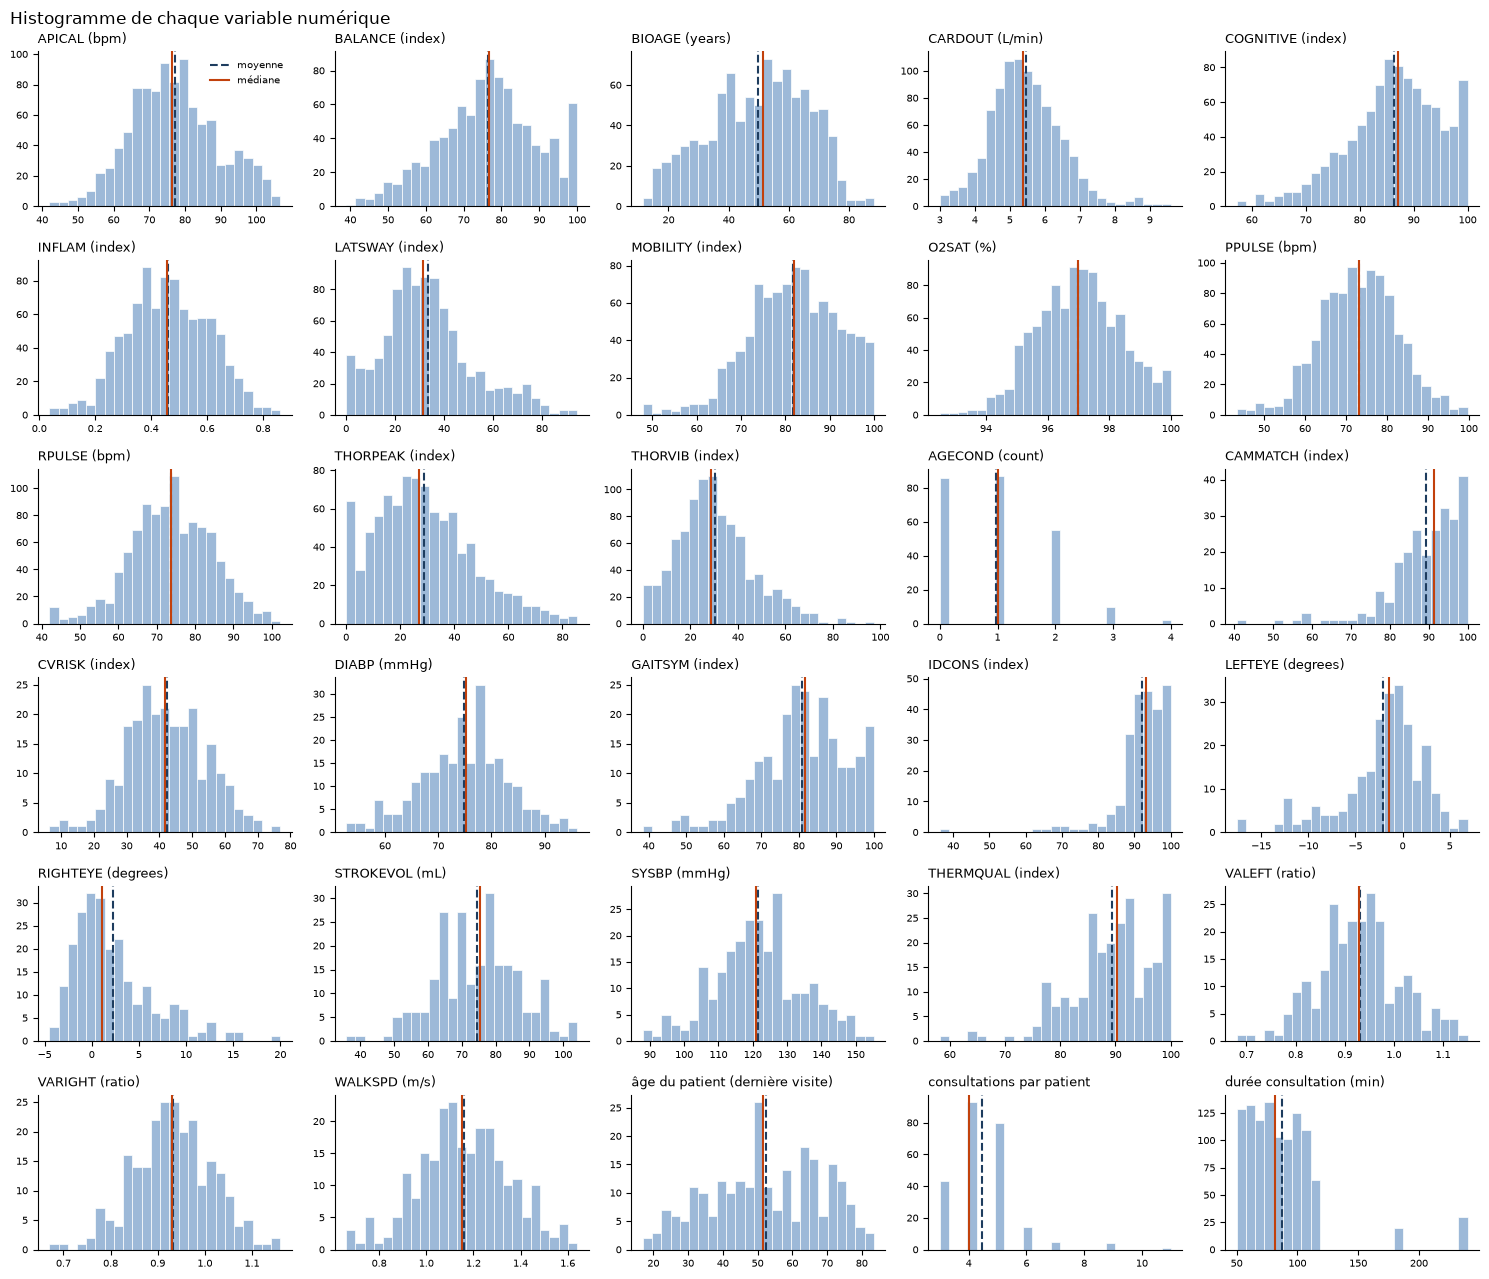

In [4]:
fig, axes = plt.subplots(6, 5, figsize=(15, 13))
for ax, (nom, s) in zip(axes.flat, variables.items()):
    s = s.dropna()
    ax.hist(s, bins=25, color="#9db9d8", edgecolor="white", linewidth=0.5)
    ax.axvline(s.mean(), color="#1d3c5e", linewidth=1.5, linestyle="--", label="moyenne")
    ax.axvline(s.median(), color="#c2410c", linewidth=1.5, label="médiane")
    titre = f"{nom} ({CAT.loc[nom, 'unite']})" if nom in CAT.index and isinstance(CAT.loc[nom, "unite"], str) else nom
    ax.set_title(titre, fontsize=9, loc="left")
    ax.tick_params(labelsize=7)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
for ax in list(axes.flat)[len(variables):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7, frameon=False)
fig.suptitle("Histogramme de chaque variable numérique", x=.01, ha="left")
plt.tight_layout(); plt.show()

**Ce qu'on voit :**
* La plupart des mesures physiologiques (pouls, tension, débit cardiaque, inflammation, acuité visuelle) ont une **forme en cloche**. Moyenne et médiane sont alors presque confondues.
* Beaucoup de **scores sont bloqués à 100** (équilibre, mobilité, cognition, reconnaissance caméra, cohérence d'identité…). La vraie valeur peut être plus haute, mais l'échelle s'arrête là : ces variables sont tronquées.
* Les indices thoraciques (`THORPEAK`, `THORVIB`) et le balancement (`LATSWAY`) ont beaucoup de zéros et une **longue queue vers le haut** : la plupart des patients n'ont rien, quelques-uns ont des valeurs élevées.
* À l'inverse, la cohérence d'identité (`IDCONS`) et la reconnaissance caméra (`CAMMATCH`) sont presque toujours élevées, avec **quelques patients très en dessous**. C'est la forme typique d'une variable où une minorité se distingue.
* L'âge biologique (`BIOAGE`) descend jusqu'à 11 ans, alors que tous les patients ont au moins 15 ans.
* Chaque patient a 3 à 5 consultations en général, mais quelques-uns en ont beaucoup plus (jusqu'à 11). On les retrouvera plus loin.

### 1.4 Variables nominales

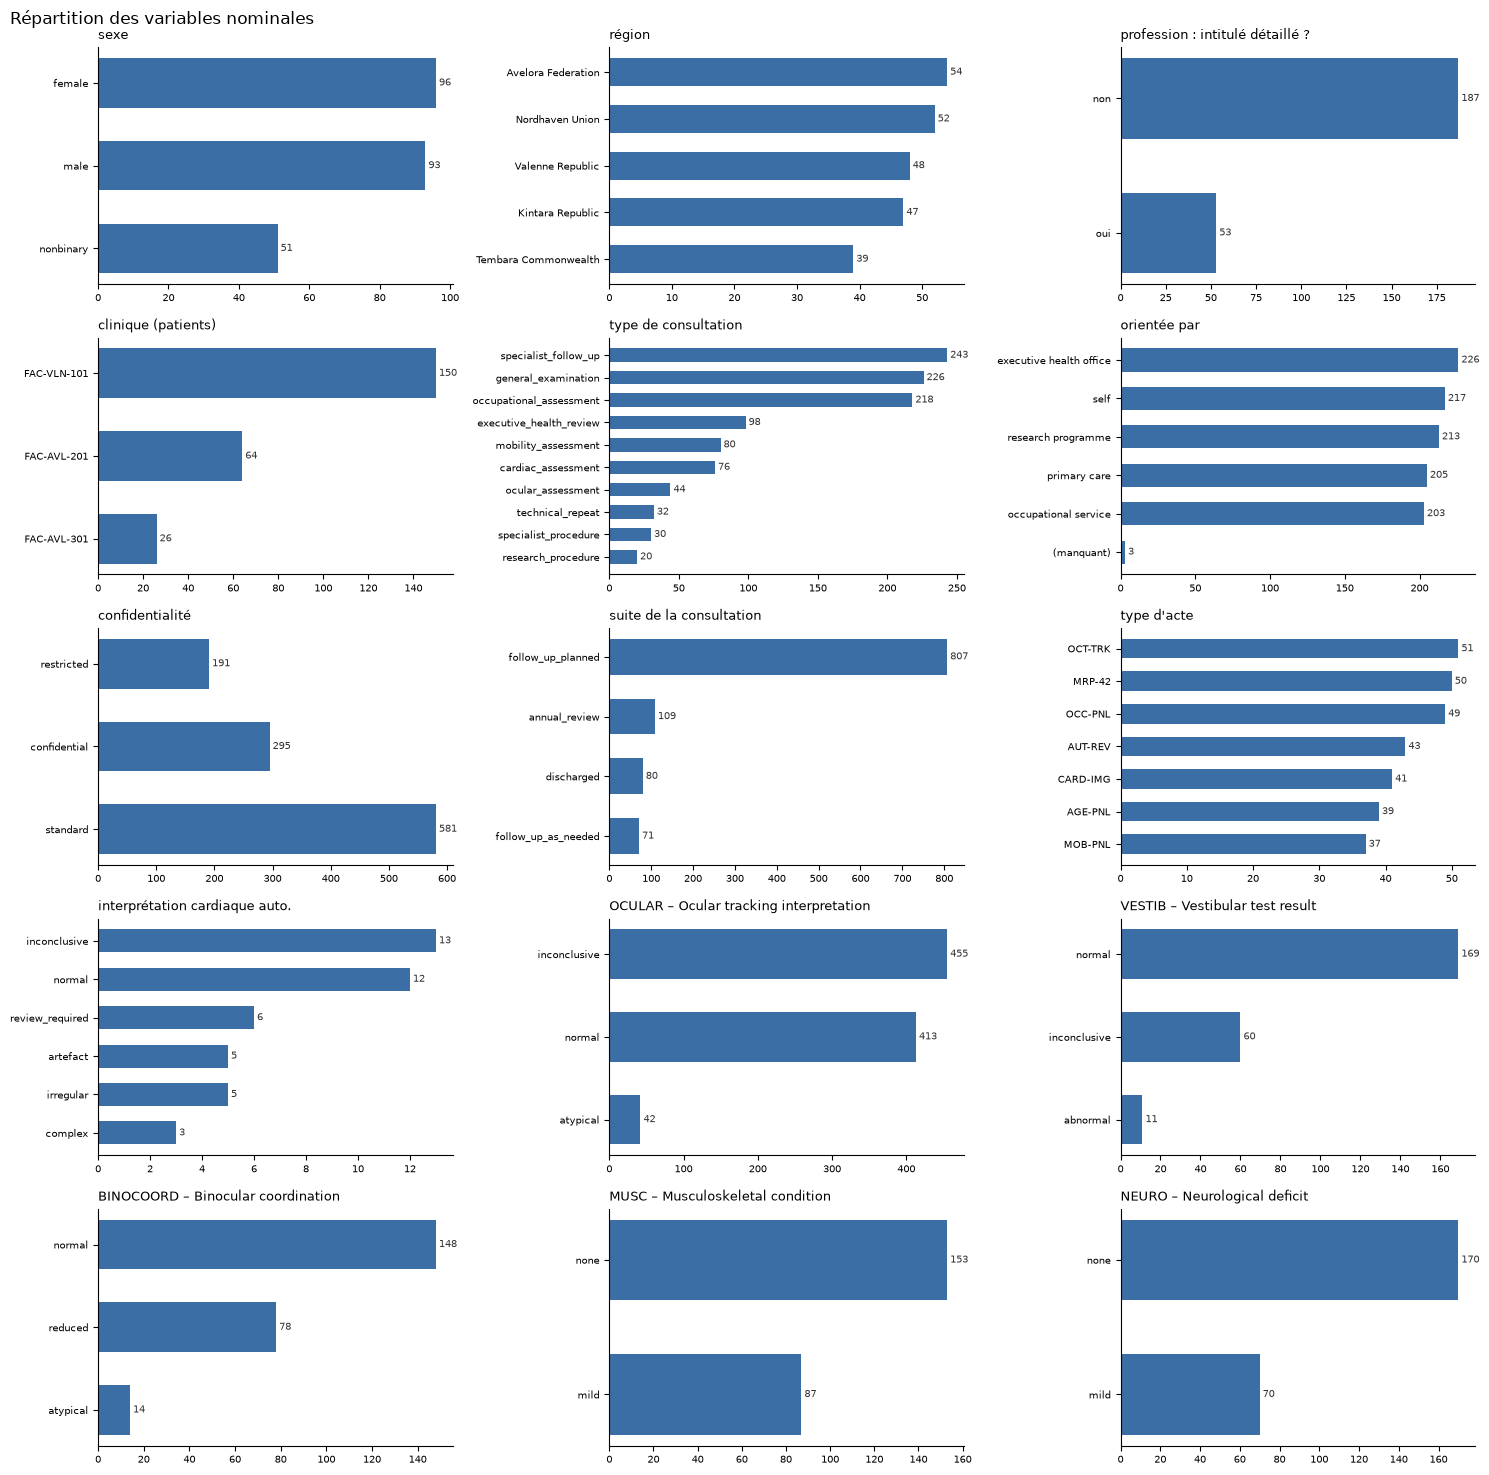

In [5]:
textes_conso = O[O["observation_code"].isin(["OCULAR", "VESTIB", "BINOCOORD", "MUSC", "NEURO"])]
nominales = {
    "sexe": P["registered_sex"],
    "région": P["home_region"],
    "profession : intitulé détaillé ?": P["occupation_detaillee"].map({True: "oui", False: "non"}),
    "clinique (patients)": P["primary_facility_license"],
    "type de consultation": E["encounter_type"],
    "orientée par": E["referral_source"].fillna("(manquant)"),
    "confidentialité": E["confidentiality_class"],
    "suite de la consultation": E["disposition"],
    "type d'acte": PR["procedure_code"],
    "interprétation cardiaque auto.": CR["automated_interpretation"],
} | {f"{c} – {CAT.loc[c, 'nom']}": textes_conso.loc[textes_conso["observation_code"] == c, "text_value"]
     for c in ["OCULAR", "VESTIB", "BINOCOORD", "MUSC", "NEURO"]}
ORDRE = {"confidentialité": ["standard", "confidential", "restricted"]}

fig, axes = plt.subplots(5, 3, figsize=(15, 15))
for ax, (nom, s) in zip(axes.flat, nominales.items()):
    vc = s.value_counts()
    vc = vc.reindex(ORDRE[nom]) if nom in ORDRE else vc.sort_values()
    ax.barh(vc.index.astype(str), vc.values, color="#3b6ea5", height=0.6)
    for y, v in enumerate(vc.values):
        ax.text(v, y, f" {v}", va="center", fontsize=7, color="#333")
    ax.set_title(nom, fontsize=9, loc="left")
    ax.tick_params(labelsize=7)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
for ax in list(axes.flat)[len(nominales):]:
    ax.axis("off")
fig.suptitle("Répartition des variables nominales", x=.01, ha="left")
plt.tight_layout(); plt.show()

**Ce qu'on voit :**
* Les patients sont répartis assez équitablement entre les sexes et les 5 régions. Les deux tiers dépendent de la clinique principale `FAC-VLN-101`.
* Les cinq origines d'orientation sont presque à égalité (environ 210 consultations chacune). Pour un hôpital réel, ce serait surprenant : l'« executive health office », un service réservé aux dirigeants, y est aussi fréquent que le médecin traitant.
* Près de la moitié des consultations sont confidentielles ou restreintes.
* Les actes sont répartis à peu près également entre les 7 types, dont 50 `MRP-42`, l'administration de produit déjà repérée au nettoyage.
* Pour les mesures en texte, le suivi oculaire est « inconclusive » dans environ la moitié des cas et « atypical » dans 42 cas. La coordination des yeux est « atypical » chez 14 patients.

### 1.5 Corrélations

On calcule les deux coefficients du cours :
* **Pearson** suppose une relation en ligne droite et est sensible aux valeurs extrêmes ;
* **Spearman** travaille sur les rangs : il détecte toute relation qui monte ou descend régulièrement, et quelques points extrêmes l'influencent peu.

Les cartes ci-dessous montrent Spearman, pour chacun des deux tableaux.

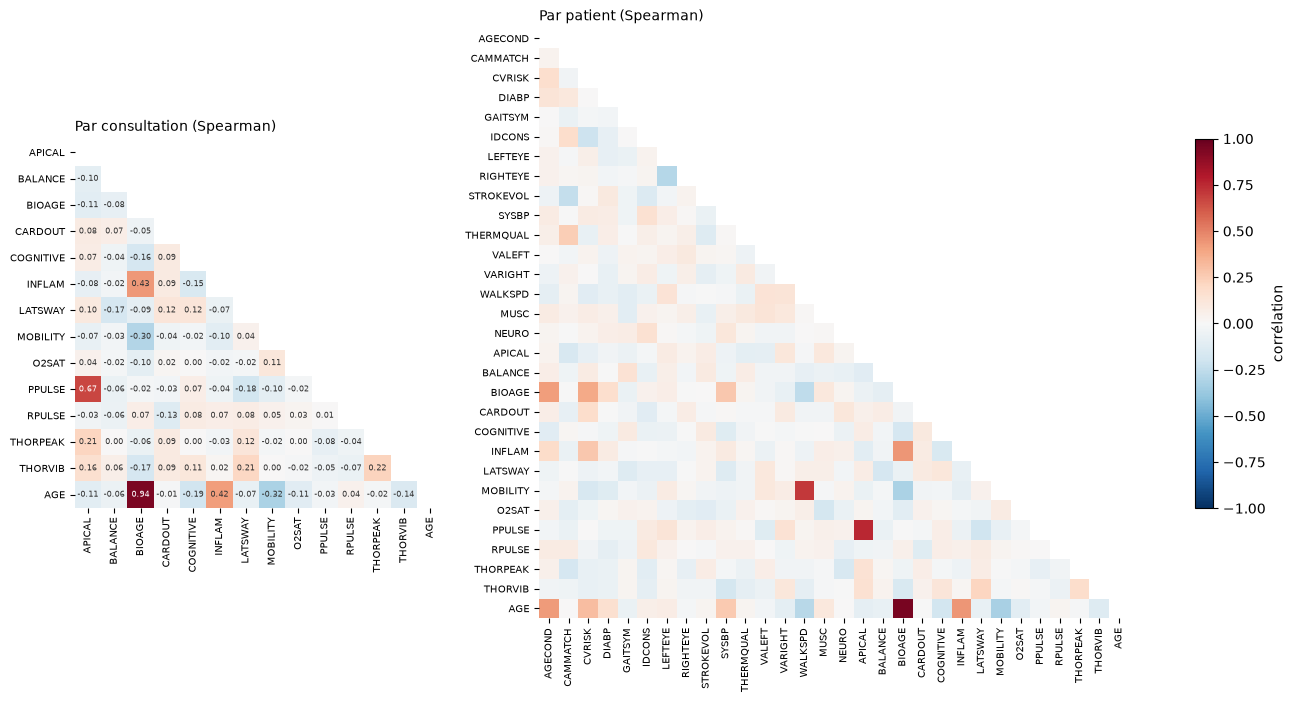

In [6]:
def carte(corr, titre, ax, annoter):
    masque = np.triu(np.ones_like(corr, dtype=bool))
    im = ax.imshow(corr.mask(masque), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.index, fontsize=7)
    if annoter:
        for i in range(len(corr)):
            for j in range(i):
                ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(corr.iat[i, j]) > .6 else "#333")
    ax.set_title(titre, fontsize=10, loc="left")
    for side in ax.spines.values():
        side.set_visible(False)
    return im

num_conso = conso[REPETEES + ["AGE"]]
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1, 1.6]})
carte(num_conso.corr("spearman"), "Par consultation (Spearman)", axes[0], True)
im = carte(patient.corr("spearman"), "Par patient (Spearman)", axes[1], False)
fig.colorbar(im, ax=axes, shrink=.6, label="corrélation")
plt.show()

In [7]:
def paires(tab, niveau):
    s, p = tab.corr("spearman"), tab.corr("pearson")
    cols = tab.columns
    return pd.DataFrame([(niveau, a, b, s.loc[a, b], p.loc[a, b])
                         for i, a in enumerate(cols) for b in cols[i + 1:]],
                        columns=["niveau", "variable 1", "variable 2", "spearman", "pearson"])

toutes = pd.concat([paires(num_conso, "consultation"), paires(patient, "patient")])
toutes["écart"] = toutes["pearson"] - toutes["spearman"]

print("Paires les plus corrélées (|Spearman| ≥ 0.3) :")
display(toutes[toutes["spearman"].abs() >= .3].sort_values("spearman", key=abs, ascending=False).round(2))
print("Paires où Pearson et Spearman diffèrent le plus :")
display(toutes.sort_values("écart", key=abs, ascending=False).head(6).round(2))

Paires les plus corrélées (|Spearman| ≥ 0.3) :


,niveau,variable 1,variable 2,spearman,pearson,écart
379,patient,BIOAGE,AGE,0.95,0.95,-0.00
35,consultation,BIOAGE,AGE,0.94,0.94,-0.00
352,patient,APICAL,PPULSE,0.75,0.76,0.00
308,patient,WALKSPD,MOBILITY,0.71,0.73,0.02
8,consultation,APICAL,PPULSE,0.67,0.67,0.00
371,patient,BIOAGE,INFLAM,0.45,0.43,-0.01
406,patient,INFLAM,AGE,0.44,0.43,-0.01
27,consultation,BIOAGE,INFLAM,0.43,0.42,-0.01
28,patient,AGECOND,AGE,0.42,0.42,-0.01
17,patient,AGECOND,BIOAGE,0.42,0.41,-0.01


Paires où Pearson et Spearman diffèrent le plus :


,niveau,variable 1,variable 2,spearman,pearson,écart
32,patient,CAMMATCH,IDCONS,0.18,0.46,0.28
148,patient,IDCONS,CARDOUT,-0.11,-0.29,-0.18
157,patient,IDCONS,THORVIB,-0.09,-0.27,-0.17
46,patient,CAMMATCH,CARDOUT,-0.08,-0.22,-0.14
432,patient,THORPEAK,THORVIB,0.18,0.31,0.13
151,patient,IDCONS,LATSWAY,-0.08,-0.21,-0.13


**Ce qu'on voit :**
* L'**âge biologique suit de très près l'âge réel** (0,95), ce qui est attendu. Il est aussi lié à l'inflammation, au nombre d'affections liées à l'âge et au risque cardiovasculaire.
* **Le pouls pris au cœur (`APICAL`) et celui pris au poignet (`PPULSE`)** sont liés (0,75), mais moins qu'on ne l'attendrait pour deux mesures du même battement : chez certains patients, les deux ne concordent pas.
* La vitesse de marche et le score de mobilité vont ensemble (0,71), ce qui est logique.
* Toutes les autres corrélations sont faibles : la plupart des mesures sont **indépendantes** les unes des autres.
* Pour quelques paires, **Pearson est bien plus fort que Spearman** : reconnaissance caméra / cohérence d'identité (0,46 contre 0,18), et les indices thoraciques entre eux. D'après le cours, cela veut dire que la relation est portée par **quelques points extrêmes** et non par l'ensemble des patients. Un petit groupe de patients cumule donc des valeurs anormales sur ces deux mesures à la fois.

### 1.6 Forme des relations

On trace les 6 paires les plus parlantes, au niveau patient. En orange, les 53 patients dont la profession a un intitulé détaillé (repérés au nettoyage). Sur les deux premiers graphiques, la diagonale indique où les points devraient se trouver si les deux mesures étaient égales.

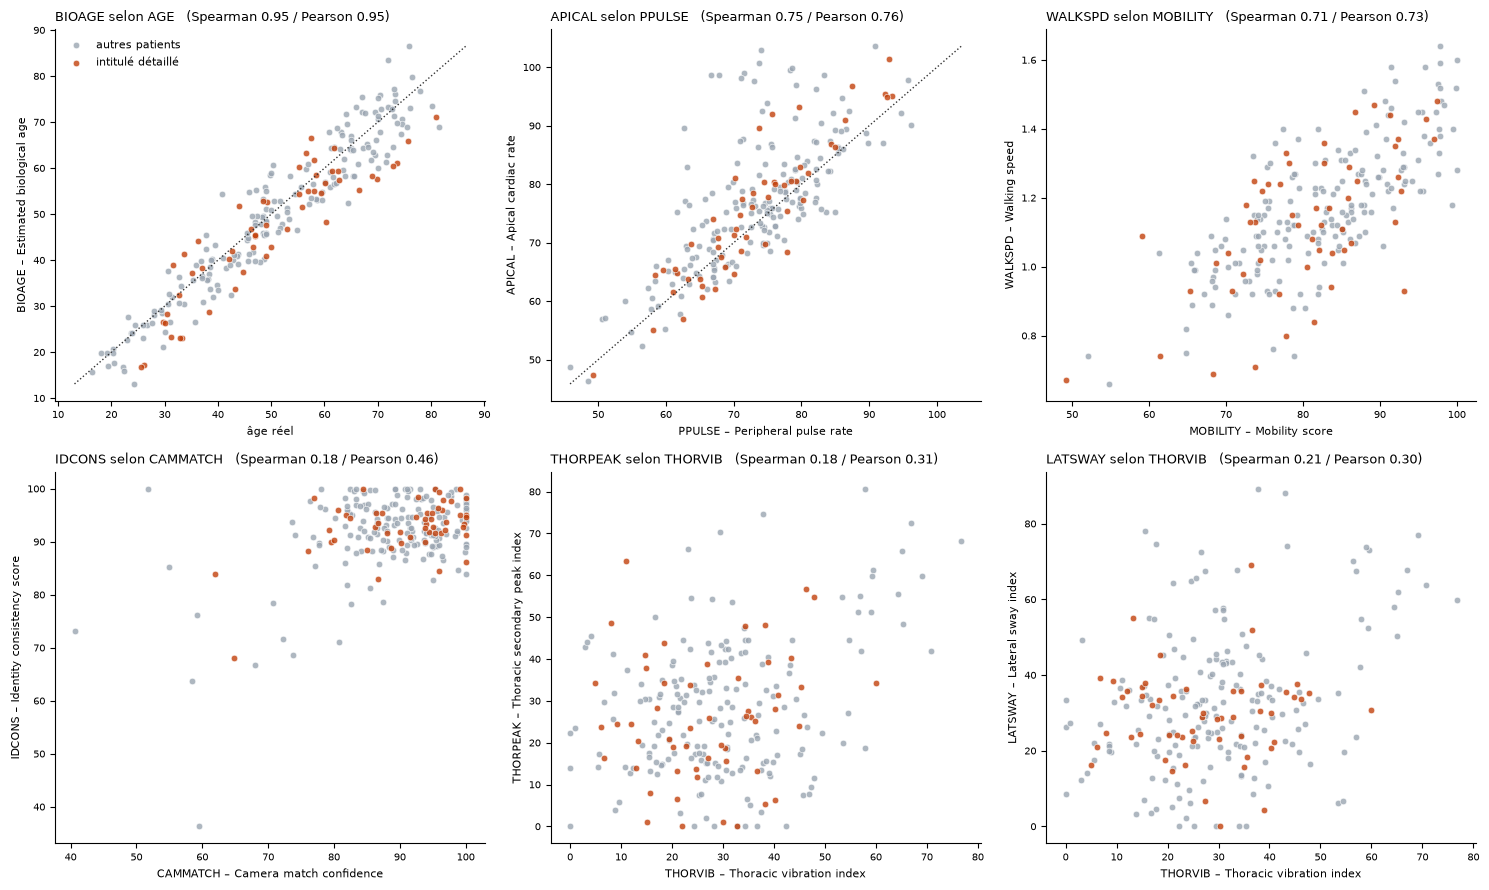

In [8]:
detail = P.set_index("patient_number")["occupation_detaillee"].reindex(patient.index)
couples = [("AGE", "BIOAGE", True), ("PPULSE", "APICAL", True), ("MOBILITY", "WALKSPD", False),
           ("CAMMATCH", "IDCONS", False), ("THORVIB", "THORPEAK", False), ("THORVIB", "LATSWAY", False)]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (x, y, diagonale) in zip(axes.flat, couples):
    for groupe, couleur, label in [(False, "#9aa5b1", "autres patients"), (True, "#c2410c", "intitulé détaillé")]:
        m = detail == groupe
        ax.scatter(patient.loc[m, x], patient.loc[m, y], s=22, color=couleur, alpha=.8,
                   edgecolor="white", linewidth=.5, label=label)
    if diagonale:
        lim = [patient[[x, y]].min().min(), patient[[x, y]].max().max()]
        ax.plot(lim, lim, color="#333", linewidth=1, linestyle=":")
    r_s, r_p = patient[[x, y]].corr("spearman").iat[0, 1], patient[[x, y]].corr("pearson").iat[0, 1]
    ax.set_title(f"{y} selon {x}   (Spearman {r_s:.2f} / Pearson {r_p:.2f})", fontsize=9, loc="left")
    ax.set_xlabel(f"{x} – {CAT.loc[x, 'nom']}" if x in CAT.index else "âge réel", fontsize=8)
    ax.set_ylabel(f"{y} – {CAT.loc[y, 'nom']}", fontsize=8)
    ax.tick_params(labelsize=7)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes.flat[0].legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**Ce qu'on voit :**
* **Âge biologique / âge réel** : la relation est **linéaire**. La plupart des patients sont proches de la diagonale, les points orange plutôt un peu en dessous, c'est-à-dire « plus jeunes » biologiquement. Quelques patients, orange ou gris, sont nettement en dessous.
* **Pouls cœur / poignet** : linéaire aussi, mais une dizaine de patients sont **très au-dessus de la diagonale**, avec un cœur qui bat 25 à 30 fois de plus par minute que le pouls mesuré au poignet. Ce sont presque tous des points gris.
* **Mobilité / vitesse de marche** : relation **croissante et linéaire**, sans point particulier. C'est une relation « normale », qui sert de point de comparaison.
* **Caméra / identité**, **indices thoraciques** : la relation n'est **ni linéaire ni croissante** dans l'ensemble. On voit un nuage sans tendance, plus quelques patients isolés dans un coin (identité et caméra très basses, ou indices thoraciques très hauts). Ce sont eux qui font monter Pearson.

On regarde qui sont les patients isolés sur les deux premiers graphiques.

In [9]:
profil = patient[["AGE", "BIOAGE", "PPULSE", "APICAL", "IDCONS", "CAMMATCH"]].copy()
profil["écart âge"] = profil["BIOAGE"] - profil["AGE"]
profil["écart pouls"] = profil["APICAL"] - profil["PPULSE"]
profil = profil.join(P.set_index("patient_number")["occupation_text"])

print("Les 8 âges biologiques les plus « jeunes » par rapport à l'âge réel :")
display(profil.nsmallest(8, "écart âge").round(1))
print("Les 8 plus grands écarts entre pouls au cœur et au poignet :")
display(profil.nlargest(8, "écart pouls").round(1))

Les 8 âges biologiques les plus « jeunes » par rapport à l'âge réel :


,AGE,BIOAGE,PPULSE,APICAL,IDCONS,CAMMATCH,écart âge,écart pouls,occupation_text
patient_number,,,,,,,,,
PAT-31016,81.4,68.8,75.3,74.9,98.5,91.1,-12.6,-0.4,research assistant
PAT-31221,72.9,60.6,68.1,67.5,94.3,94.7,-12.4,-0.6,Head of government of Kintara Republic
PAT-31074,73.6,61.2,71.1,68.6,91.7,88.0,-12.4,-2.5,Executive chair of Nivren Maritime Logistics
PAT-31119,69.8,57.6,59.6,65.4,95.1,100.0,-12.2,5.8,Chief executive of Solvane Energy Group
PAT-31183,60.3,48.4,71.0,74.7,95.4,86.4,-11.9,3.7,Executive director of Ardena Capital Union
PAT-31178,64.3,52.5,79.8,76.8,96.1,90.4,-11.8,-3.1,agricultural worker
PAT-31044,66.5,55.2,67.0,74.1,95.4,87.3,-11.2,7.1,Senior minister of the Avelora Federation
PAT-31077,24.2,13.1,75.5,86.8,92.9,81.6,-11.1,11.3,small-business owner


Les 8 plus grands écarts entre pouls au cœur et au poignet :


,AGE,BIOAGE,PPULSE,APICAL,IDCONS,CAMMATCH,écart âge,écart pouls,occupation_text
patient_number,,,,,,,,,
PAT-31209,38.8,40.1,66.6,98.6,86.8,93.5,1.3,32.0,administrative employee
PAT-31065,46.5,41.8,67.8,98.6,91.3,74.1,-4.7,30.8,clinical specialist
PAT-31101,22.5,16.0,74.0,103.0,88.5,87.2,-6.5,28.9,transport worker
PAT-31037,33.1,34.4,71.6,99.0,66.7,68.0,1.3,27.4,research professional
PAT-31073,63.3,67.2,73.7,100.8,99.7,91.3,3.9,27.1,teacher
PAT-31086,48.8,55.8,71.2,98.1,76.2,59.2,7.1,26.9,corporate adviser
PAT-31215,45.6,39.9,62.7,89.6,78.2,82.6,-5.7,26.9,research professional
PAT-31186,51.3,46.2,73.0,97.7,96.7,81.9,-5.1,24.7,corporate adviser


### 1.7 Ce qu'on retient du cours 1

1. **Deux tendances se dessinent, mais elles ne forment pas encore des groupes nets :**
   * un **âge biologique plus jeune que l'âge réel** : 5 des 8 écarts les plus forts concernent des dirigeants (chef de gouvernement, ministre, PDG…), mais on y trouve aussi un ouvrier agricole, un assistant de recherche et un petit commerçant ;
   * un **pouls au cœur qui ne correspond pas au pouls au poignet** : parmi les 8 plus grands écarts, 4 patients ont une profession discrète (`research professional`, `corporate adviser`, `clinical specialist`), mais on trouve aussi une employée, un chauffeur et un enseignant. Plusieurs de ces patients ont aussi une cohérence d'identité basse.

   Ces deux tendances ne touchent pas les mêmes patients. Le regroupement du cours 2 devra dire s'il s'agit de vrais groupes ou de cas isolés.
2. La plupart des mesures sont **indépendantes**. Les rares liens forts sont attendus (âge biologique et âge réel, mobilité et vitesse de marche), et les liens « anormaux » viennent de quelques patients seulement. C'est un bon signe que l'histoire cachée concerne une **minorité**.
3. Plusieurs variables sont **bloquées à 100** ou ont une **longue queue**. Pour les comparaisons, Spearman est plus fiable que Pearson.
4. Pour le cours 2, on peut retirer les variables qui se répètent : l'âge biologique se résume mieux par son **écart à l'âge réel**, et les deux pouls par leur **écart**. On réduit ainsi le nombre de variables tout en gardant l'information utile.

*Rappel : une corrélation ne prouve pas une cause. Ces observations sont des pistes que les cours suivants (regroupement, anomalies) doivent confirmer.*

## Cours 2 — Ordonner et regrouper ses données

*(à venir)*